In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

data = pd.read_csv("data.csv")
print(data.head())


     area  bedrooms  age     price
0  2104.0       3.0    5  399900.0
1  1600.0       3.0   39  329900.0
2  2400.0       3.0   33  369000.0
3  1416.0       2.0   22  232000.0
4  3000.0       4.0   22  539900.0


In [4]:
print(data.info())

<class 'pandas.DataFrame'>
RangeIndex: 47 entries, 0 to 46
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   size      47 non-null     float64
 1   bedrooms  47 non-null     float64
 2   price     47 non-null     float64
dtypes: float64(3)
memory usage: 1.2 KB
None


In [21]:
x = data.iloc[:, :-1].values
y = data.iloc[:, -1].values

In [22]:
mean = np.mean(x, axis=0)
std = np.std(x, axis=0)
x = (x-mean)/std


In [20]:
def hypothesis(x, w):
  return np.dot(x, w)


In [23]:
x = np.c_[np.ones(x.shape[0]), x]
#np_c[]-> concatinates (join) array colyumn wise. turns the 1D array and turns it into a vertical column and ataches it to the left of the x 

In [24]:
def cost_function(x, y, w, lam):
  m = len(y)
  prediction = hypothesis(x, w)
  error = prediction - y
  reg = (lam/(2*m)) * np.sum(w[1:]**2)
  cost = (1/(2*m))*np.sum(error**2)
  return cost + reg

In [28]:
def gradient_descent(x, y, w, learning_rate, lam, iterations):
    m = len(y)
    cost_history = []

    for _ in range(iterations):
        prediction = hypothesis(x, w)
        error = prediction - y

        gradient = (1 / m) * np.dot(x.T, error)
        gradient[1:] += (lam / m) * w[1:]

        w = w - learning_rate * gradient
        cost_history.append(cost_function(x, y, w, lam))

    return w, cost_history

w = np.zeros(x.shape[1]) #craates 1D filled with zeros
learning_rate = 0.05
lambda_value = 1.5
iterations = 800

w, cost_history = gradient_descent(
    x, y, w, learning_rate, lambda_value, iterations
)

print("Final weights:", w)
print("Final regularized cost:", cost_history[-1])

Final weights: [340412.65957447 104426.15857008  -4132.61796386   1198.51808704]
Final regularized cost: 2225546503.9090133


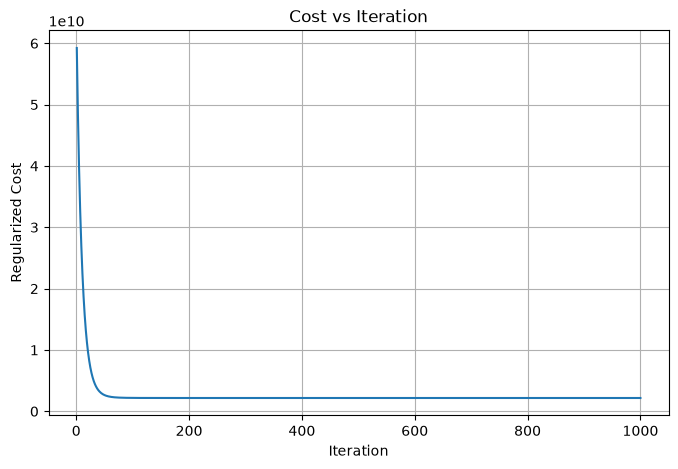

In [26]:
plt.figure(figsize=(8, 5))
plt.plot(range(1, iterations + 1), cost_history)
plt.xlabel("Iteration")
plt.ylabel("Regularized Cost")
plt.title("Cost vs Iteration")
plt.grid(True)
plt.show()

In [27]:
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error

# Use the scaled features before adding the bias column
scaled_features = (data.iloc[:, :-1].values - mean) / std

sklearn_model = Ridge(alpha=lambda_value)
sklearn_model.fit(scaled_features, y)
sklearn_predictions = sklearn_model.predict(scaled_features)

scratch_predictions = hypothesis(x, w)

scratch_mse = mean_squared_error(y, scratch_predictions)
sklearn_mse = mean_squared_error(y, sklearn_predictions)

print("Scratch MSE:", scratch_mse)
print("Scikit-learn MSE:", sklearn_mse)
print("Scratch weights:", w)
print("Scikit-learn weights:", np.r_[sklearn_model.intercept_, sklearn_model.coef_])

Scratch MSE: 4093371269.20678
Scikit-learn MSE: 4093371269.144301
Scratch weights: [340412.65957447 106017.22784206  -5033.36861886   1162.43698097]
Scikit-learn weights: [340412.65957447 106017.22785507  -5033.36863524   1162.43698665]
